Libraries imported successfully.


Saving hdr_general.csv to hdr_general (1).csv
Dataset loaded successfully!
Shape: 6798 rows, 33 columns
Number of rows (records)  : 6798
Number of columns (fields): 33
Column names in the dataset:

 1. Unnamed: 0
 2. iso3
 3. country
 4. hdicode
 5. hdi_rank_2022
 6. gii_rank_2022
 7. year
 8. hdi
 9. life_expectancy
10. pop_millions
11. hdi_f
12. hdi_m
13. life_expec_f
14. life_expec_m
15. expec_yr_school
16. expec_yr_school_f
17. expec_yr_school_m
18. mean_yr_school
19. mean_yr_school_f
20. mean_yr_school_m
21. gross_inc_percap
22. gross_inc_percap_f
23. gross_inc_percap_m
24. gender_development
25. gender_inequality
26. secondary_education_f_%
27. secondary_education_m_%
28. seats_in_parliament_f_%
29. seats_in_parliament_m_%
30. labour_participation_f_%
31. labour_participation_m_%
32. co2_emission_tons
33. mat_footprint_percap_tons
                           Missing Count  Missing %
gender_inequality                   2087      30.70
gender_development                  1784      2

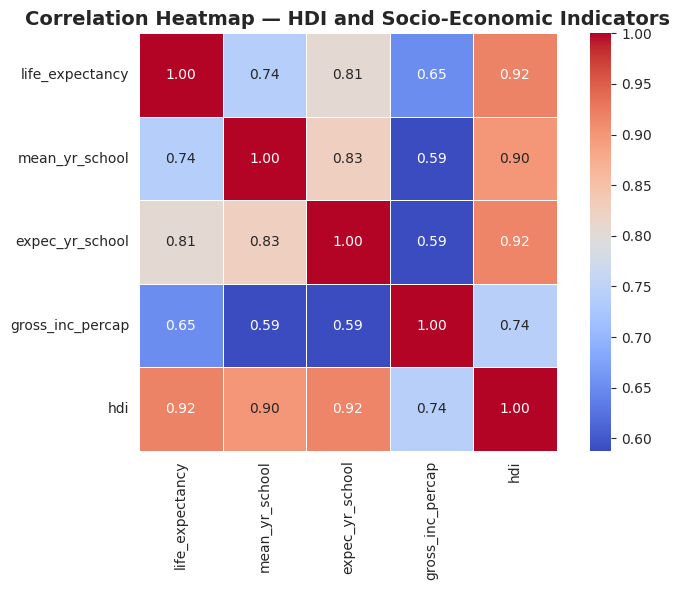

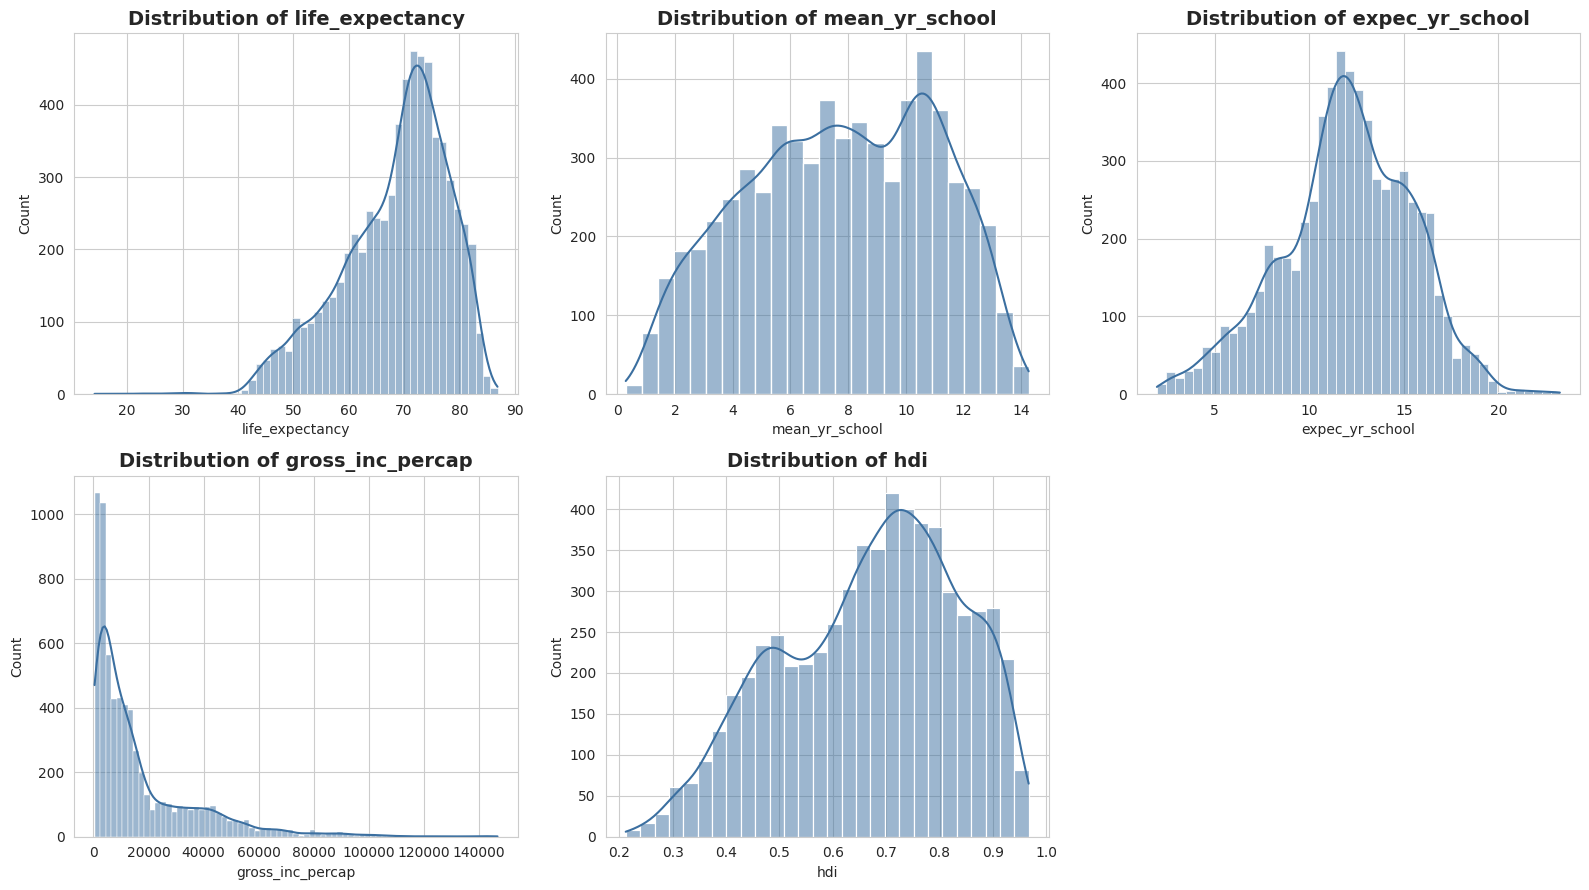

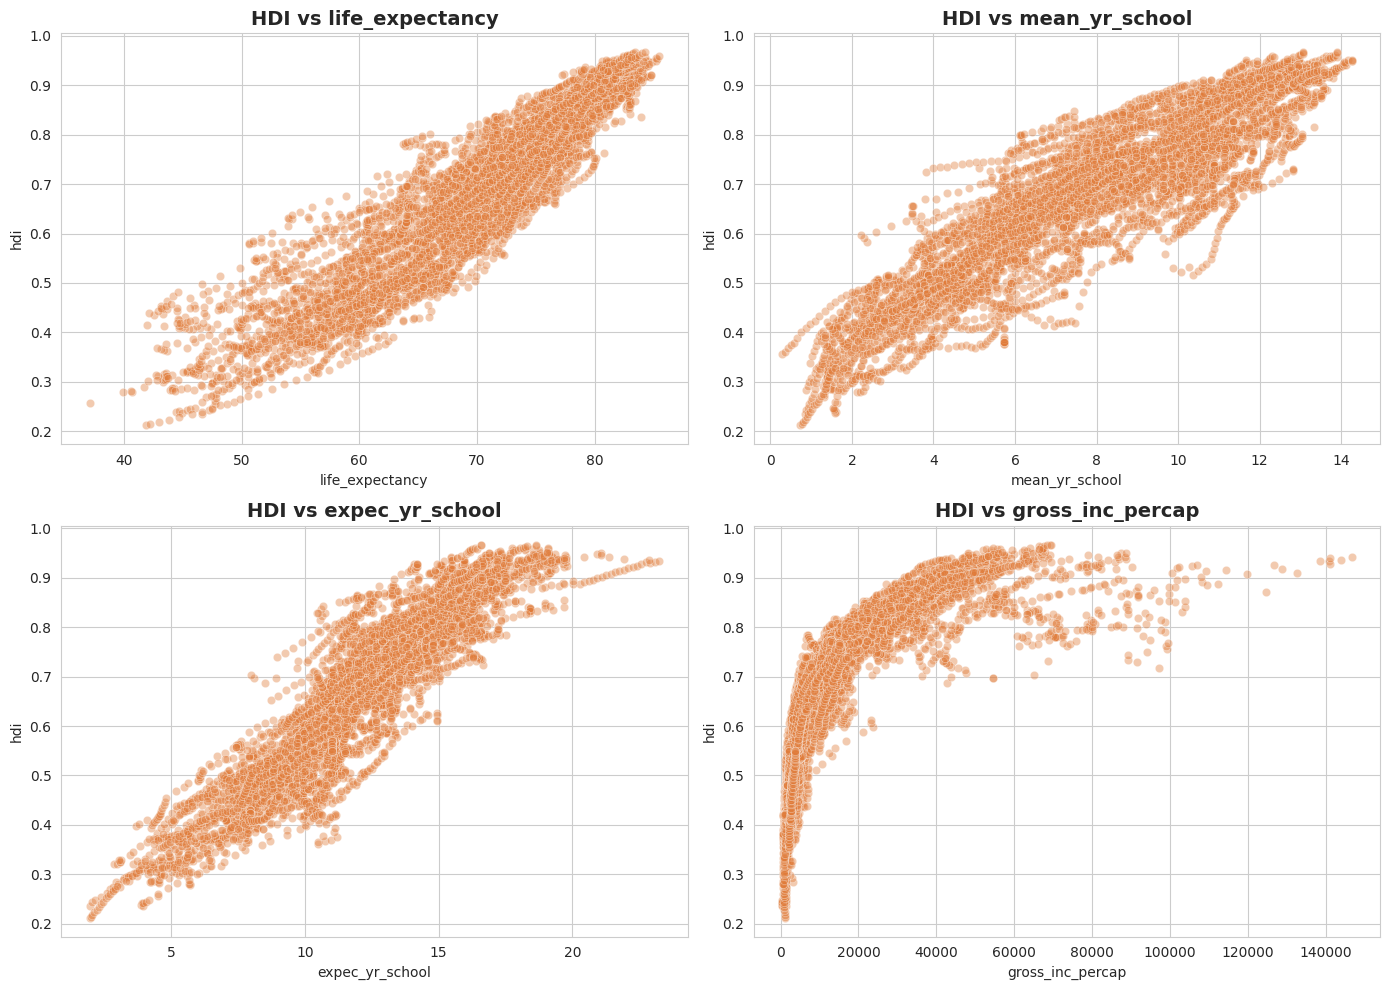

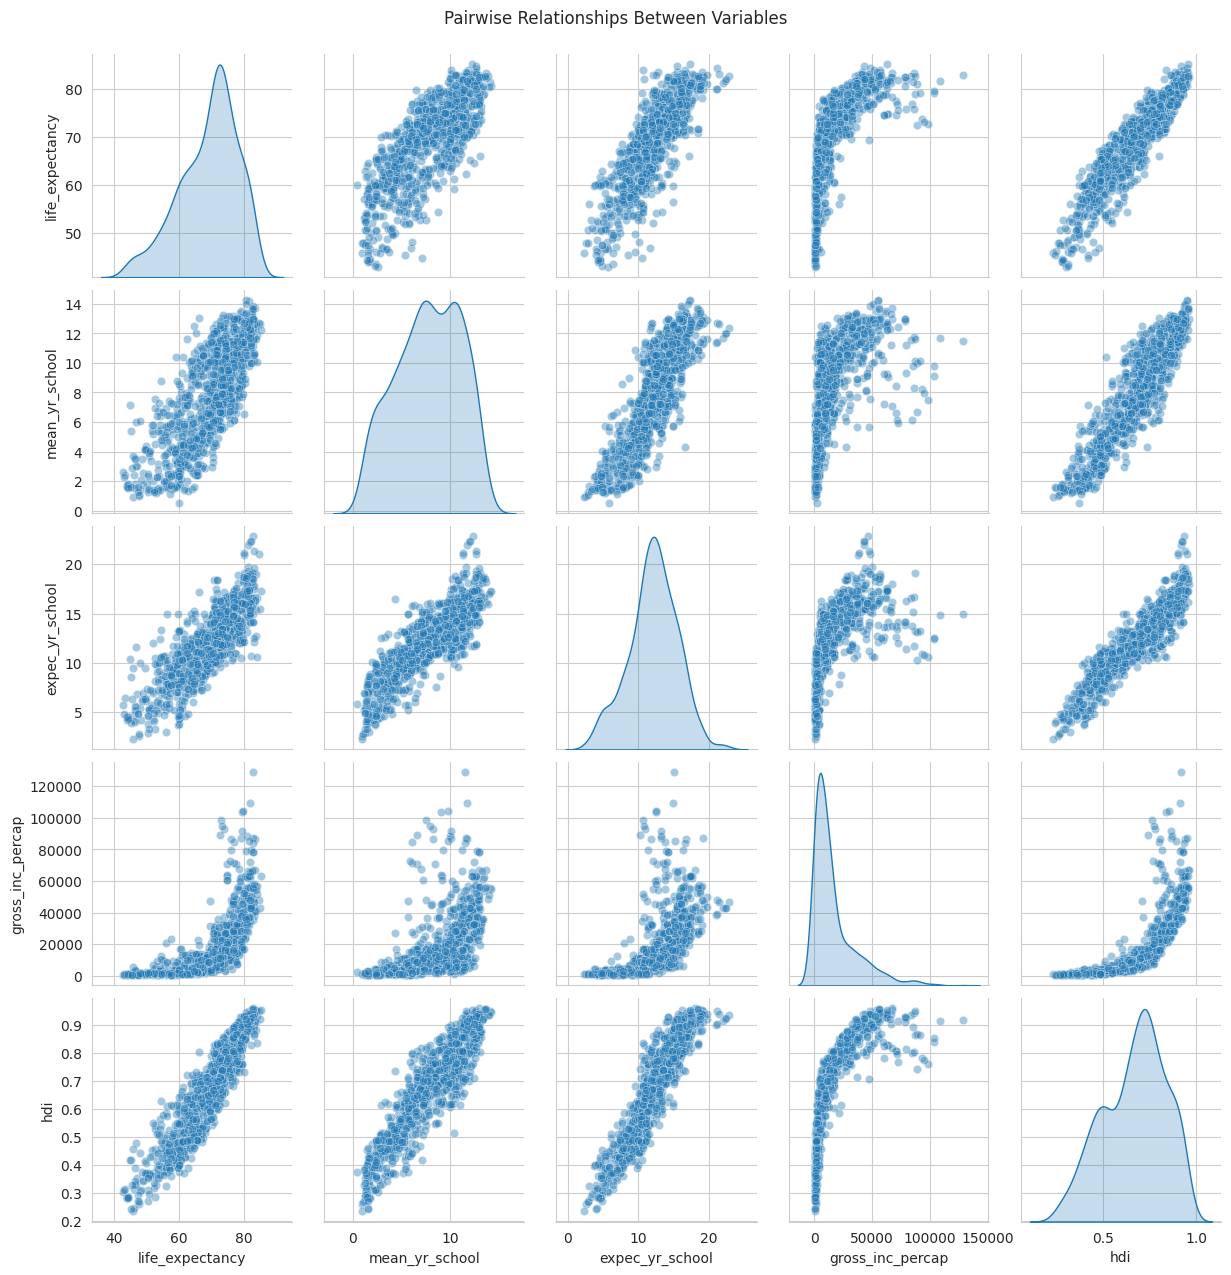

Rows before removing missing values: 6798
Rows after removing missing values : 6171
Rows removed: 627
Rows before removing duplicates: 6171
Rows after removing duplicates : 6171
Original categories : ['Low', 'High', 'Very High', 'Medium']
Encoded as numbers  : ['High', 'Low', 'Medium', 'Very High']
Shape of X (features): (6171, 4)
Shape of y (target)  : (6171,)
Final cleaned dataset: 6171 rows, 5 columns
Training set size: 4936 rows (80.0%)
Testing set size : 1235 rows (20.0%)
Model training complete!
Model Coefficients (impact of each feature on HDI):
         Feature  Coefficient
  mean_yr_school     0.015265
 expec_yr_school     0.013953
 life_expectancy     0.006593
gross_inc_percap     0.000001

Intercept (baseline HDI value): -0.095163
Predictions generated for 1235 test samples.
        MODEL EVALUATION METRICS
Mean Absolute Error (MAE) : 0.01692
Mean Squared Error  (MSE) : 0.00050
Root Mean Squared Error   : 0.02227
R-squared (R2 Score)      : 0.98196


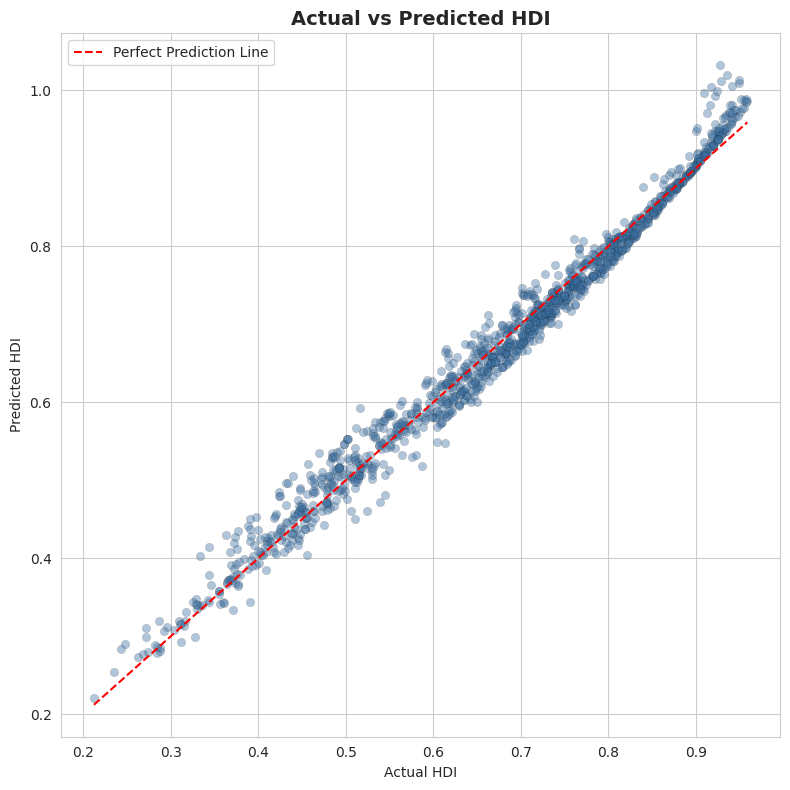

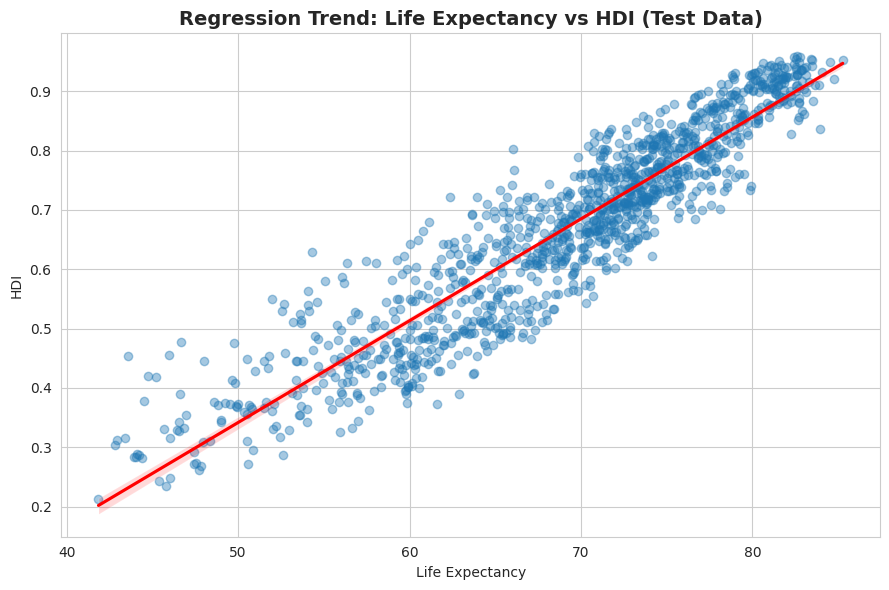

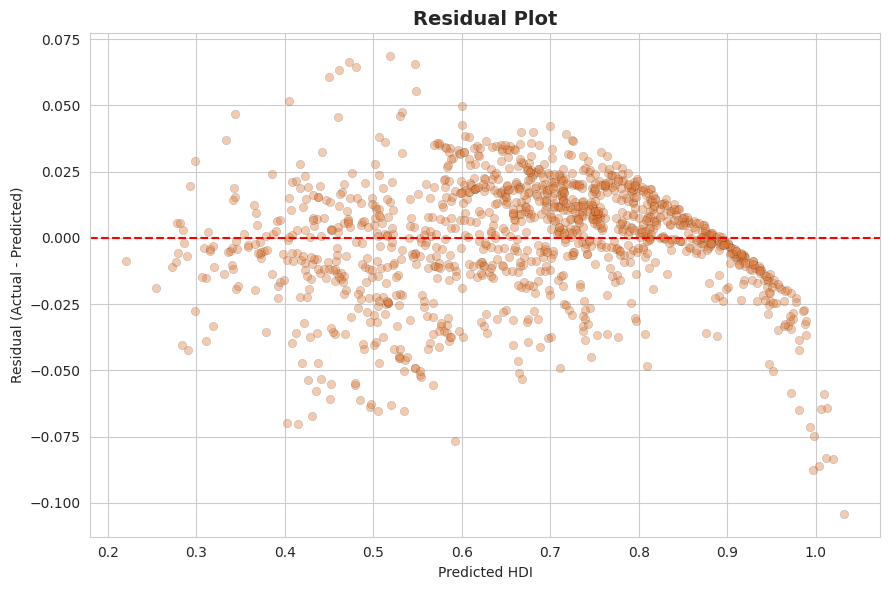

Model saved successfully as 'hdi_model.pkl'
Model loaded successfully from disk.
Predicted HDI for sample input: 0.7224


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# HDI PREDICTION — LINEAR REGRESSION
# ============================================================

# STEP 3.1 — Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"

print("Libraries imported successfully.")
# STEP 3.2 — Load the dataset
# Upload hdr_general.csv using the file icon on the left sidebar in Colab,
# or run this to get an upload dialog:
from google.colab import files
uploaded = files.upload()

DATA_PATH = "hdr_general.csv"

# This CSV is NOT plain UTF-8 (has accented country names), so we must
# specify encoding='latin1' or pandas will throw a UnicodeDecodeError.
df = pd.read_csv(DATA_PATH, encoding="latin1")

print("Dataset loaded successfully!")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
# STEP 3.3 — First five rows
df.head()
# STEP 3.4 — Dataset shape
print(f"Number of rows (records)  : {df.shape[0]}")
print(f"Number of columns (fields): {df.shape[1]}")
# STEP 3.5 — Column names
print("Column names in the dataset:\n")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:2d}. {col}")
    # STEP 3.6 — Data types
df.dtypes
# STEP 3.7 — Summary statistics
df.describe()
# STEP 3.8 — Check for missing values
missing_values = df.isnull().sum()
missing_percent = (missing_values / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing %": missing_percent.round(2)
}).sort_values(by="Missing Count", ascending=False)

print(missing_report[missing_report["Missing Count"] > 0])
# STEP 3.9 — Check duplicate records
duplicate_count = df.duplicated().sum()
print(f"Number of fully duplicated rows: {duplicate_count}")
# STEP 3.10 — Unique values for key columns
print("Unique HDI categories (hdicode):", df["hdicode"].unique())
print("Number of unique countries      :", df["country"].nunique())
print("Year range covered              :", df["year"].min(), "-", df["year"].max())
# STEP 3.11 — Isolate the columns relevant to our prediction task
project_cols = ["life_expectancy", "mean_yr_school", "expec_yr_school",
                 "gross_inc_percap", "hdi"]

df_project = df[project_cols].copy()
df_project.head()
# STEP 3.12 — Correlation Heatmap
plt.figure(figsize=(8, 6))
correlation_matrix = df_project.corr()
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f",
            linewidths=0.5, square=True)
plt.title("Correlation Heatmap — HDI and Socio-Economic Indicators")
plt.tight_layout()
plt.show()
# STEP 3.13 — Histograms
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(project_cols):
    sns.histplot(df_project[col].dropna(), kde=True, ax=axes[i], color="#3b6fa0")
    axes[i].set_title(f"Distribution of {col}")

axes[-1].axis("off")
plt.tight_layout()
plt.show()
# STEP 3.14 — Scatter plots (each feature vs HDI)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
features = ["life_expectancy", "mean_yr_school", "expec_yr_school", "gross_inc_percap"]

for i, feature in enumerate(features):
    sns.scatterplot(data=df_project, x=feature, y="hdi", ax=axes[i],
                     alpha=0.4, color="#e07b39")
    axes[i].set_title(f"HDI vs {feature}")

plt.tight_layout()
plt.show()
# STEP 3.15 — Pair plot
sample_df = df_project.dropna().sample(n=min(1000, len(df_project.dropna())), random_state=42)
sns.pairplot(sample_df, diag_kind="kde", plot_kws={"alpha": 0.4})
plt.suptitle("Pairwise Relationships Between Variables", y=1.02)
plt.show()
# STEP 4.1 — Handle missing values
# Rows missing ANY of our 5 project columns are dropped (keeps all
# training data 100% real/observed — no guessed values).
print("Rows before removing missing values:", len(df_project))
df_clean = df_project.dropna()
print("Rows after removing missing values :", len(df_clean))
print(f"Rows removed: {len(df_project) - len(df_clean)}")
# STEP 4.2 — Remove duplicate rows
print("Rows before removing duplicates:", len(df_clean))
df_clean = df_clean.drop_duplicates()
print("Rows after removing duplicates :", len(df_clean))
# STEP 4.3 — (Demonstration) Label Encoding of a categorical column
# hdicode (Low/Medium/High/Very High) is categorical. We show LabelEncoder
# here for completeness — it is NOT used as a model input, since our
# actual features/target are already numeric.
from sklearn.preprocessing import LabelEncoder

demo_categorical = df.loc[df_clean.index, "hdicode"].dropna()
label_encoder = LabelEncoder()
encoded_demo = label_encoder.fit_transform(demo_categorical)

print("Original categories :", list(demo_categorical.unique()))
print("Encoded as numbers  :", list(label_encoder.classes_))
# STEP 4.4 — Select independent variables (X) and dependent variable (y)
X = df_clean[["life_expectancy", "mean_yr_school", "expec_yr_school", "gross_inc_percap"]]
y = df_clean["hdi"]

print("Shape of X (features):", X.shape)
print("Shape of y (target)  :", y.shape)
# STEP 4.5 — Display the cleaned dataset
df_clean.reset_index(drop=True, inplace=True)
print(f"Final cleaned dataset: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns")
df_clean.head(10)
# STEP 5.1 — Train/Test Split (80:20)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training set size: {X_train.shape[0]} rows ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Testing set size : {X_test.shape[0]} rows ({X_test.shape[0]/len(X)*100:.1f}%)")
# STEP 6.1 — Train the Linear Regression model
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)
print("Model training complete!")
# STEP 6.2 — Coefficients and intercept
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
}).sort_values(by="Coefficient", key=abs, ascending=False)

print("Model Coefficients (impact of each feature on HDI):")
print(coefficients.to_string(index=False))
print(f"\nIntercept (baseline HDI value): {model.intercept_:.6f}")
# STEP 6.3 — Predict on test data
y_pred = model.predict(X_test)
print("Predictions generated for", len(y_pred), "test samples.")
# STEP 6.4 — Compare actual vs predicted values
comparison_df = pd.DataFrame({
    "Actual HDI": y_test.values,
    "Predicted HDI": y_pred,
    "Difference": y_test.values - y_pred
}).reset_index(drop=True)

comparison_df.head(15)
# STEP 6.5 — Evaluate the model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("="*45)
print("        MODEL EVALUATION METRICS")
print("="*45)
print(f"Mean Absolute Error (MAE) : {mae:.5f}")
print(f"Mean Squared Error  (MSE) : {mse:.5f}")
print(f"Root Mean Squared Error   : {rmse:.5f}")
print(f"R-squared (R2 Score)      : {r2:.5f}")
print("="*45)
# STEP 6.6 — Graph: Actual vs Predicted
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred, alpha=0.4, color="#3b6fa0", edgecolor="k", linewidth=0.2)

min_val, max_val = y_test.min(), y_test.max()
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--",
         label="Perfect Prediction Line")

plt.xlabel("Actual HDI")
plt.ylabel("Predicted HDI")
plt.title("Actual vs Predicted HDI")
plt.legend()
plt.tight_layout()
plt.show()
# STEP 6.7 — Graph: Regression trend (strongest single feature vs HDI)
plt.figure(figsize=(9, 6))
sns.regplot(x=X_test["life_expectancy"], y=y_test, scatter_kws={"alpha": 0.4},
            line_kws={"color": "red"})
plt.xlabel("Life Expectancy")
plt.ylabel("HDI")
plt.title("Regression Trend: Life Expectancy vs HDI (Test Data)")
plt.tight_layout()
plt.show()
# STEP 6.8 — Graph: Residual Plot
residuals = y_test.values - y_pred

plt.figure(figsize=(9, 6))
plt.scatter(y_pred, residuals, alpha=0.4, color="#e07b39", edgecolor="k", linewidth=0.2)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted HDI")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()
# STEP 7.1 — Save the trained model using Pickle
import pickle

MODEL_FILENAME = "hdi_model.pkl"
with open(MODEL_FILENAME, "wb") as file:
    pickle.dump(model, file)

print(f"Model saved successfully as '{MODEL_FILENAME}'")
# STEP 7.2 — Load the saved model again
with open(MODEL_FILENAME, "rb") as file:
    loaded_model = pickle.load(file)

print("Model loaded successfully from disk.")
# STEP 7.3 — Demonstrate prediction using the loaded model
sample_input = pd.DataFrame({
    "life_expectancy": [72.5],
    "mean_yr_school": [9.2],
    "expec_yr_school": [13.1],
    "gross_inc_percap": [12500]
})

predicted_hdi = loaded_model.predict(sample_input)
print(f"Predicted HDI for sample input: {predicted_hdi[0]:.4f}")
# STEP 7.4 — Download the model file to your computer
from google.colab import files
files.download("hdi_model.pkl")
